# Aufgabe 12.3 – Klassifikation mit einem Time Series Forest

**Ziel:** UWaveGestureLibrary mit aeons TimeSeriesForestClassifier klassifizieren
und den TEST-Erfolg mit den freigegebenen kNN-/CNN-Ergebnissen aus 12.2 vergleichen.
Quellen: [offizielle Exercise 12.3](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/8_self_study_session3.html),
[Kursabschnitt 8.1](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/4_1_timeseries_classification.html),
[aeon 1.6 API](https://www.aeon-toolkit.org/en/stable/api_reference/auto_generated/aeon.classification.interval_based.TimeSeriesForestClassifier.html),
gelesen am 26.10.2026. Datenherkunft und Katalogabweichung: `docs/UWAVE_SOURCE.md`.
KI-Unterstützung: Codex. **AWAITING HUMAN REVIEW – NOT MERGED.**

## Daten und Vergleichsbedingungen
Die Originaldateien enthalten 120 TRAIN- und 320 TEST-Gesten, acht Klassen,
drei Kanäle und je 315 Werte. Keine zufällige Neuaufteilung, keine fehlenden Werte,
keine Imputation oder Längenanpassung. Physikalische Zeiteinheiten sind nicht belegt.
Der Kanalskalierer wird ausschließlich auf TRAIN geschätzt und auf TEST angewendet.
Bäume brauchen diese Skalierung nicht; sie hält hier die Eingabebedingungen zu 12.2 gleich.
Die bereits bekannten Testergebnisse dienen nur zum Vergleich, nicht zur Modellwahl.

## Warum ein Intervall-Forest?
Ein Baum erhält Mittelwert, Standardabweichung und Steigung zufälliger Kanalintervalle.
Damit beschreibt er lokale Lage, Streuung und Entwicklung statt aller Rohwerte einzeln.
Für ein Intervall mit L Werten gilt μ = Σxᵢ/L und σ² = Σ(xᵢ−μ)²/L.
Die lineare Steigung ist b = Σ(tᵢ−t̄)(xᵢ−μ)/Σ(tᵢ−t̄)², tᵢ=0,…,L−1.
Ihre Einheit ist standardisierter Signalwert pro Abtastschritt, nicht pro Sekunde.

200 Entropie-Entscheidungsbäume werden mit unterschiedlichen Intervallen trainiert.
Die mittlere Blatt-Klassenwahrscheinlichkeit entscheidet per argmax; bei Gleichstand
nimmt diese aeon-Version die erste Klasse. Das ist keine geprüfte Kalibrierung.
Die reguläre Implementierung nutzt alle TRAIN-Fälle je Baum, keine Bootstrap-Fallauswahl.
Im multivariaten aeon-Code bedeutet `sqrt` hier int(√315·√3)=30 Intervallziehungen
je Baum; Duplikate können entfallen. Ein Intervall gehört zu einem zufälligen Kanal.
Alle Einstellungen sind vor dem Training festgelegt: minimale Länge 3, Seed 42,
200 Bäume, ein CPU-Thread, kein Zeitlimit, keine Hyperparametersuche.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sessions.ch12.classification import load_uwave, transform, evaluate
from sessions.ch12.forest import CONFIG, fit_forest, predict_forest, load_reference, first_interval

ROOT=Path.cwd()
OUT=ROOT/'outputs/ch12/exercise_12_3';OUT.mkdir(parents=True,exist_ok=True)
x_train,y_train=load_uwave('TRAIN')
x_test,y_test=load_uwave('TEST')
reference,provenance=load_reference(y_test)
model,scaler,fit_seconds=fit_forest(x_train,y_train)
y_forest,probabilities,predict_seconds=predict_forest(model,scaler,x_test)
predictions={'DTW 3-NN':reference.knn.to_numpy(),'CNN':reference.cnn.to_numpy(),'Time Series Forest':y_forest}
metrics,matrices,reports=evaluate(y_test,predictions,model.classes_)
metrics['correct']=[int(np.trace(matrices[name])) for name in metrics.method]
metrics.to_csv(OUT/'metrics.csv',index=False)
reports.to_csv(OUT/'classification_report.csv',index=False)
reference.assign(forest=y_forest).to_csv(OUT/'predictions.csv',index=False)
pd.DataFrame(probabilities,columns=model.classes_).to_csv(OUT/'forest_probabilities.csv',index=False)
for name,matrix in matrices.items():
    if name=='Time Series Forest':pd.DataFrame(matrix,index=model.classes_,columns=model.classes_).to_csv(OUT/'confusion_forest.csv')
paired=[]
for name in ['DTW 3-NN','CNN']:
    old=predictions[name]==y_test;new=y_forest==y_test
    paired.append({'reference':name,'both_correct':int((old&new).sum()),'forest_only_correct':int((~old&new).sum()),'reference_only_correct':int((old&~new).sum()),'both_wrong':int((~old&~new).sum())})
pd.DataFrame(paired).to_csv(OUT/'paired_comparison.csv',index=False)
example=first_interval(model,transform(x_train,scaler))
summary={'train_shape':list(x_train.shape),'test_shape':list(x_test.shape),'classes':model.classes_.tolist(),'missing':int(np.isnan(x_train).sum()+np.isnan(x_test).sum()),'config':CONFIG,'actual_trees':len(model.estimators_),'interval_draws':model.total_intervals_,'unique_intervals_per_tree':[len(tree[0].intervals_)//3 for tree in model.intervals_],'train_mean':scaler[0].ravel().tolist(),'train_scale':scaler[1].ravel().tolist(),'fit_seconds':fit_seconds,'predict_seconds':predict_seconds,'example':example,'reference':provenance}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')
display(metrics.round(6))
print(f'Forest: {len(model.estimators_)} Bäume; {model.total_intervals_} Ziehungen/Baum; Fit {fit_seconds:.4f} s; Predict {predict_seconds:.4f} s (zusätzlicher Probability-Aufruf nicht enthalten).')

,method,accuracy,balanced_accuracy,macro_f1,correct
0,DTW 3-NN,0.909375,0.909375,0.908593,291
1,CNN,0.846875,0.846875,0.846505,271
2,Time Series Forest,0.865625,0.865625,0.863884,277


Forest: 200 Bäume; 30 Ziehungen/Baum; Fit 5.6534 s; Predict 0.9894 s (zusätzlicher Probability-Aufruf nicht enthalten).


## Ein tatsächlich verwendetes Intervall
Die folgende Darstellung zeigt den ersten gezogenen Kanalabschnitt des ersten Baums
für die erste TRAIN-Geste. Die drei Merkmale werden zusätzlich direkt nachgerechnet.
Die Auswahl ist ein Einblick in die Merkmalsbildung, keine Wichtigkeitsanalyse.

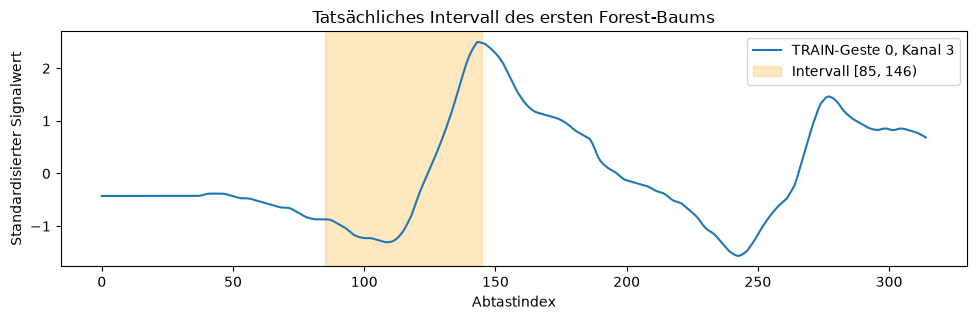

,start,end_exclusive,channel,dilation,mean,std,slope
0,85,146,2,1,-0.165286,1.275381,0.062555


In [2]:
channel=example['channel'];start=example['start'];end=example['end_exclusive']
values=transform(x_train,scaler)[0,channel]
fig,ax=plt.subplots(figsize=(10,3.3))
ax.plot(np.arange(315),values,label=f'TRAIN-Geste 0, Kanal {channel+1}')
ax.axvspan(start,end-1,color='orange',alpha=.25,label=f'Intervall [{start}, {end})')
ax.set(title='Tatsächliches Intervall des ersten Forest-Baums',xlabel='Abtastindex',ylabel='Standardisierter Signalwert')
ax.legend(loc='best');fig.tight_layout();fig.savefig(OUT/'01_interval.png',dpi=150);plt.show()
display(pd.DataFrame([example]).round(6))

## TEST-Ergebnisse und Vergleich
Die Confusion-Matrix zählt wahre Klassen zeilenweise und Vorhersagen spaltenweise.
Accuracy misst den Anteil korrekter Gesten; Macro-F1 gewichtet jede Klasse gleich.
Weil jede TEST-Klasse 40 Fälle enthält, entspricht Balanced Accuracy hier Accuracy.
Die gepaarte Tabelle zeigt, ob der Forest dieselben oder andere Fälle richtig löst.
Es wird keine Signifikanz oder allgemeine Rangfolge aus dem einzelnen Split abgeleitet.

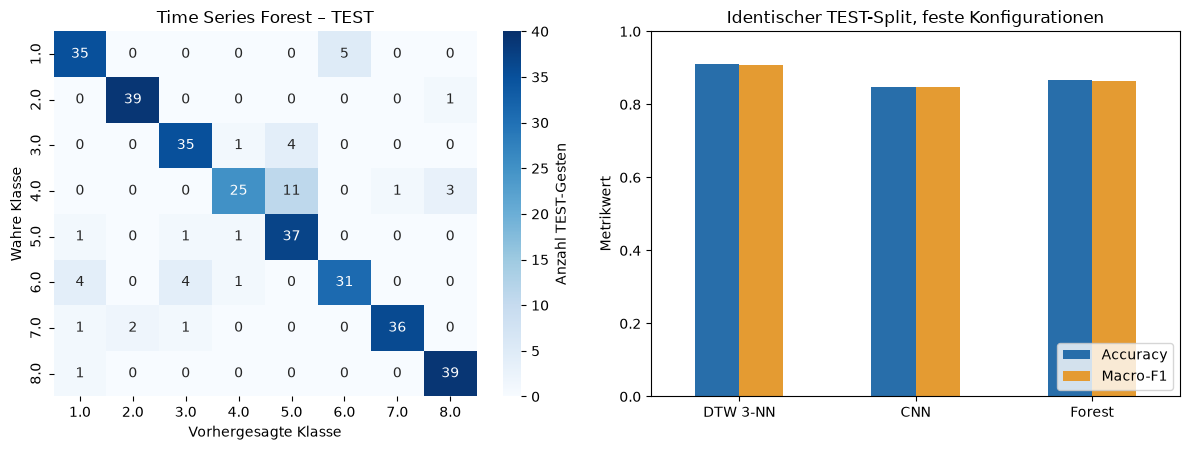

,method,class,precision,recall,f1-score,support
16,Time Series Forest,1.0,0.8333,0.875,0.8537,40.0
17,Time Series Forest,2.0,0.9512,0.975,0.9630,40.0
18,Time Series Forest,3.0,0.8537,0.875,0.8642,40.0
19,Time Series Forest,4.0,0.8929,0.625,0.7353,40.0
20,Time Series Forest,5.0,0.7115,0.925,0.8043,40.0
21,Time Series Forest,6.0,0.8611,0.775,0.8158,40.0
22,Time Series Forest,7.0,0.9730,0.900,0.9351,40.0
23,Time Series Forest,8.0,0.9070,0.975,0.9398,40.0


,reference,both_correct,forest_only_correct,reference_only_correct,both_wrong
0,DTW 3-NN,270,7,21,22
1,CNN,261,16,10,33


**Beobachtung:** Forest 277/320 korrekt, Accuracy 0.865625, Macro-F1 0.863884. Accuracy-Differenz gegenüber kNN -4.3750 und gegenüber CNN +1.8750 Prozentpunkte. Die Frage nach besseren Ergebnissen wird anhand dieser konkreten Differenzen beantwortet, ohne Parameter nachträglich anzupassen.

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
sns.heatmap(matrices['Time Series Forest'],annot=True,fmt='d',cmap='Blues',vmin=0,vmax=40,xticklabels=model.classes_,yticklabels=model.classes_,ax=axes[0],cbar_kws={'label':'Anzahl TEST-Gesten'})
axes[0].set(title='Time Series Forest – TEST',xlabel='Vorhergesagte Klasse',ylabel='Wahre Klasse')
comparison=metrics.set_index('method')[['accuracy','macro_f1']].rename(columns={'accuracy':'Accuracy','macro_f1':'Macro-F1'})
comparison.plot.bar(ax=axes[1],rot=0,color=['#286eaa','#e49b32'])
axes[1].set(title='Identischer TEST-Split, feste Konfigurationen',ylabel='Metrikwert',xlabel='',ylim=(0,1))
axes[1].set_xticklabels(['DTW 3-NN','CNN','Forest']);axes[1].legend(loc='lower right')
fig.tight_layout();fig.savefig(OUT/'02_comparison.png',dpi=150);plt.show()
display(reports[reports.method=='Time Series Forest'].round(4));display(pd.DataFrame(paired))
forest_score=metrics.set_index('method').loc['Time Series Forest']
knn_score=metrics.set_index('method').loc['DTW 3-NN'];cnn_score=metrics.set_index('method').loc['CNN']
display(Markdown(f"**Beobachtung:** Forest {int(forest_score.correct)}/320 korrekt, Accuracy {forest_score.accuracy:.6f}, Macro-F1 {forest_score.macro_f1:.6f}. Accuracy-Differenz gegenüber kNN {100*(forest_score.accuracy-knn_score.accuracy):+.4f} und gegenüber CNN {100*(forest_score.accuracy-cnn_score.accuracy):+.4f} Prozentpunkte. Die Frage nach besseren Ergebnissen wird anhand dieser konkreten Differenzen beantwortet, ohne Parameter nachträglich anzupassen."))

## Einordnung und Grenzen
Auf diesem Split liegt der Forest mit 277 korrekten Gesten zwischen CNN (271) und
DTW-3-NN (291): +1,8750 Prozentpunkte gegenüber CNN, −4,3750 gegenüber kNN.
Auch Macro-F1 ist höher als beim CNN und niedriger als bei kNN. Die Aufgabe nach
besseren Ergebnissen wird damit nur gegenüber dem CNN positiv beantwortet.
Gegenüber kNN löst der Forest sieben Fälle zusätzlich richtig, verliert aber 21;
gegenüber CNN sind es 16 zusätzliche und zehn verlorene Fälle. Dies erklärt die
Nettodifferenzen, ohne Unterschiede als statistisch gesichert zu bezeichnen.
Klasse 4 wird elfmal als 5 vorhergesagt, wie bei beiden Referenzverfahren;
eine Ursache lässt sich daraus nicht ableiten.

Intervallstatistiken erlauben eine kompakte Darstellung lokaler Muster, verlieren aber
Detailinformation. Anders als DTW richtet der Forest Zeitverläufe nicht elastisch aus.
Ein Unterschied auf diesem TEST-Split ist keine allgemeine Überlegenheit und belegt
keinen kausalen Grund für einzelne Klassenverwechslungen. Die Verfahren besitzen
unterschiedliche Modellannahmen; faire Datenbedingungen bedeuten keine gleiche Kapazität.

120 Trainingsfälle, ein Seed und ein bereits bekannter Benchmark reichen nicht für
Aussagen zur Seed-Stabilität, Signifikanz oder unbekannten Personen. Kein separates
Validierungsset, keine Parameteroptimierung, kein Kalibrierungsnachweis. Das Archiv
hat bereits feste Länge 315; konkrete physikalische Dauer/Auflösung ist nicht belegt.
Die abweichenden Fallzahlen der Katalogseite sind in der Datenquellendokumentation
offengelegt; hier werden alle Fälle der gehashten Originaldateien verwendet.
Zeitmessungen hängen von Hardware, Cache und Erstkompilierung ab. Die alten Modelle
werden aus ihren unveränderten freigegebenen Vorhersagen verglichen und nicht erneut
zeitlich vermessen; daher keine Rangfolge der Rechenkosten aus diesem Experiment.

**Lernfragen:** Welche Information erfassen die drei Intervallmerkmale? Warum ist
TRAIN-only-Vorverarbeitung trotz baumbasierter Modelle sinnvoll? Was müsste eine
unabhängige Validierungsstudie prüfen, bevor die beobachtete Rangfolge verallgemeinert wird?